ASSESMENT 1

Theme Park Operations
& Visitor Analytics

In [0]:
%sql
CREATE VOLUME IF NOT EXISTS workspace.default.training_files;

In [0]:
CATALOG = "workspace"
SCHEMA = "default"
BASE_PATH = "/Volumes/workspace/default/training_files"

In [0]:
display(dbutils.fs.ls("/Volumes/workspace/default/training_files"))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/training_files/attraction_maintenance.csv,attraction_maintenance.csv,1324,1794369955000
dbfs:/Volumes/workspace/default/training_files/attractions.json,attractions.json,2562,1794369955000
dbfs:/Volumes/workspace/default/training_files/databricks_dataset_setup.py,databricks_dataset_setup.py,3260,1794369955000
dbfs:/Volumes/workspace/default/training_files/park_entries.csv,park_entries.csv,8592,1794369955000
dbfs:/Volumes/workspace/default/training_files/park_entries_incremental.csv,park_entries_incremental.csv,911,1794369955000
dbfs:/Volumes/workspace/default/training_files/park_entry_changes.csv,park_entry_changes.csv,823,1794369955000


Section A: Data ingestion and exploration

In [0]:
for name in ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]:
    df = spark.table(name)
    display(df)
    print(name, df.count())

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


tp_entries_raw 121


attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


tp_attractions 10


maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


tp_maintenance 28


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


tp_entry_changes 10


In [0]:
entries_df = spark.table("tp_entries_raw")
entries_df.printSchema()
print([(f.name, f.dataType.simpleString()) for f in entries_df.schema.fields])

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

[('entry_id', 'int'), ('visitor_id', 'string'), ('attraction_id', 'string'), ('visit_date', 'string'), ('entry_time', 'string'), ('wait_minutes', 'int'), ('ride_minutes', 'int'), ('ticket_type', 'string'), ('ticket_price', 'double'), ('status', 'string'), ('booking_channel', 'string')]


In [0]:
display(
    spark.table("tp_entries_raw")
    .select("entry_id", "attraction_id", "visit_date", "ticket_type", "ticket_price")
    .limit(20)
)

entry_id,attraction_id,visit_date,ticket_type,ticket_price
1001,A08,2026-10-06,Standard,350.0
1002,A01,2026-10-10,Standard,350.0
1003,A04,2026-10-11,Standard,350.0
1004,A05,2026-10-15,Express,650.0
1005,A07,2026-10-07,Standard,350.0
1006,A08,2026-10-09,VIP,900.0
1007,A08,2026-10-14,Standard,350.0
1008,A06,2026-10-01,Express,650.0
1009,A02,2026-10-16,Standard,350.0
1010,A02,2026-10-09,Express,600.0


In [0]:
%sql
SELECT *
FROM tp_entries_raw
WHERE status = 'Completed' AND ticket_price > 500;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1022,V543,A09,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
1024,V537,A06,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App


In [0]:
%sql
SELECT DISTINCT ticket_type
FROM tp_entries_raw;

ticket_type
Standard
Express
VIP


In [0]:
%sql
SELECT DISTINCT booking_channel
FROM tp_entries_raw;

booking_channel
App
Web
Kiosk
Partner
null


In [0]:
%sql
SELECT DISTINCT ticket_type, booking_channel
FROM tp_entries_raw
WHERE ticket_type IN ('Express', 'VIP')
  AND booking_channel IN ('Web', 'App', 'Kiosk')
ORDER BY ticket_type, booking_channel;

ticket_type,booking_channel
Express,App
Express,Kiosk
Express,Web
VIP,App
VIP,Web


In [0]:
%sql
SELECT to_date(visit_date) AS visit_date, COUNT(*) AS entry_count
FROM tp_entries_raw
GROUP BY to_date(visit_date)
ORDER BY visit_date;

visit_date,entry_count
2026-10-01,11
2026-10-02,4
2026-10-03,13
2026-10-04,7
2026-10-05,4
2026-10-06,6
2026-10-07,8
2026-10-08,7
2026-10-09,10
2026-10-10,7


B. Cleaning and transforming with PySpark

In [0]:
from pyspark.sql import functions as F

entries_df = spark.table("tp_entries_raw")
attractions_df = spark.table("tp_attractions")

In [0]:
missing_df = entries_df.filter(F.col("ticket_price").isNull() | F.col("booking_channel").isNull())
display(missing_df)
print(missing_df.count())

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,null
1071,V553,A07,2026-10-03,11:10:00,5,20,Standard,null,Completed,Partner
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,null


5


In [0]:
filled_df = entries_df.fillna({"booking_channel": "Unknown"})
display(filled_df.filter(F.col("booking_channel") == "Unknown"))
print(entries_df.filter(F.col("booking_channel").isNull()).count())

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,Unknown
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,Unknown
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,Unknown


3


In [0]:
invalid_df = entries_df.filter(
    (F.col("wait_minutes") < 0) | (F.col("ride_minutes") == 0) | (F.col("ticket_price") <= 0)
)
display(invalid_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1036,V527,A06,2026-10-04,14:40:00,40,0,Standard,400.0,Completed,Kiosk
1058,V516,A02,2026-10-08,19:10:00,30,4,Standard,0.0,Completed,App
1073,V501,A03,2026-10-07,18:50:00,-3,6,Express,650.0,Completed,App


In [0]:
display(entries_df.groupBy("entry_id").count().filter(F.col("count") > 1))
dedup_df = entries_df.dropDuplicates(["entry_id"])
print(entries_df.count(), dedup_df.count())
dedup_df.createOrReplaceTempView("entries_dedup")

entry_id,count
1032,2


121 120


In [0]:
unmatched_df = dedup_df.join(attractions_df, on="attraction_id", how="left_anti")
display(unmatched_df)

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A99,1092,V566,2026-10-03,15:40:00,75,20,Standard,400.0,Completed,Kiosk


In [0]:
wait_df = (
    dedup_df
    .filter(F.col("wait_minutes") >= 0)
    .withColumn(
        "wait_category",
        F.when(F.col("wait_minutes") <= 20, "Short")
         .when(F.col("wait_minutes") <= 45, "Medium")
         .otherwise("Long")
    )
)
display(wait_df)
display(wait_df.groupBy("wait_category").count())

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,wait_category
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App,Short
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Long
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Medium
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,Short
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,Short
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,Short
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Short
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,Medium
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,Short
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk,Short


wait_category,count
Short,56
Long,31
Medium,31


In [0]:
joined_df = (
    dedup_df
    .join(attractions_df, on="attraction_id", how="left")
    .select(
        "entry_id",
        "attraction_id",
        "attraction_name",
        F.col("location.zone").alias("zone"),
        F.col("location.section").alias("section"),
        "features"
    )
)
display(joined_df)

entry_id,attraction_id,attraction_name,zone,section,features
1003,A04,Moonlight Train,West,W3,"List(Scenic, Family Friendly)"
1021,A03,Jungle Rapids,South,S1,"List(Water Ride, Outdoor)"
1030,A10,Mini Explorers,East,E3,"List(Kids, Indoor)"
1044,A04,Moonlight Train,West,W3,"List(Scenic, Family Friendly)"
1088,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"
1092,A99,null,null,null,null
1108,A03,Jungle Rapids,South,S1,"List(Water Ride, Outdoor)"
1015,A05,Meteor Drop,North,N2,"List(High Speed, Outdoor)"
1022,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"
1025,A09,Galaxy Theater,North,N3,"List(Indoor, Live Show)"


Section C: SQL joins and aggregations

In [0]:
%sql
SELECT *
FROM entries_dedup
WHERE status = 'Completed'
  AND ticket_type IN ('Standard', 'Express')
  AND ticket_price BETWEEN 300 AND 700;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner


In [0]:
%sql
SELECT e.attraction_id,
       a.attraction_name,
       SUM(CASE WHEN e.ticket_price > 0 THEN e.ticket_price END) AS valid_revenue,
       COUNT(*) AS completed_entries
FROM entries_dedup e
LEFT JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
GROUP BY e.attraction_id, a.attraction_name
ORDER BY e.attraction_id;

attraction_id,attraction_name,valid_revenue,completed_entries
A01,Sky Spinner,4200.0,9
A02,Coral Carousel,2000.0,6
A03,Jungle Rapids,4500.0,8
A04,Moonlight Train,4850.0,11
A05,Meteor Drop,5850.0,10
A06,Pirate Voyage,4600.0,9
A07,Crystal Maze,4750.0,10
A08,Forest Flyers,3600.0,8
A09,Galaxy Theater,3200.0,7
A10,Mini Explorers,6050.0,14


In [0]:
%sql
SELECT a.attraction_id,
       a.attraction_name,
       COUNT(m.maintenance_id) AS completed_jobs,
       COALESCE(SUM(m.downtime_minutes), 0) AS total_downtime_minutes
FROM tp_attractions a
LEFT JOIN tp_maintenance m
  ON a.attraction_id = m.attraction_id AND m.maintenance_status = 'Completed'
GROUP BY a.attraction_id, a.attraction_name
ORDER BY a.attraction_id;

attraction_id,attraction_name,completed_jobs,total_downtime_minutes
A01,Sky Spinner,1,120
A02,Coral Carousel,2,240
A03,Jungle Rapids,1,30
A04,Moonlight Train,2,75
A05,Meteor Drop,0,0
A06,Pirate Voyage,3,135
A07,Crystal Maze,1,120
A08,Forest Flyers,1,60
A09,Galaxy Theater,1,0
A10,Mini Explorers,1,120


In [0]:
%sql
SELECT COALESCE(a.location.zone, 'Unmatched') AS zone,
       SUM(e.ticket_price) AS completed_revenue
FROM entries_dedup e
LEFT JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed' AND e.ticket_price > 0
GROUP BY COALESCE(a.location.zone, 'Unmatched')
ORDER BY zone;

zone,completed_revenue
East,12650.0
North,13250.0
South,9250.0
Unmatched,400.0
West,8450.0


D. Delta table creation and CRUD

In [0]:
%sql
CREATE OR REPLACE TABLE tp_entries_work
USING DELTA
AS
SELECT DISTINCT
       entry_id, visitor_id, attraction_id, visit_date, entry_time,
       wait_minutes, ride_minutes, ticket_type, ticket_price, status,
       COALESCE(booking_channel, 'Unknown') AS booking_channel
FROM tp_entries_raw
WHERE wait_minutes >= 0 AND ride_minutes > 0 AND ticket_price > 0;

num_affected_rows,num_inserted_rows


In [0]:

%sql
SELECT COUNT(*) AS total_rows FROM tp_entries_work;

total_rows
114


In [0]:
from pyspark.sql import functions as F

completed_df = spark.table("tp_entries_work").filter(F.col("status") == "Completed")
completed_df.write.format("delta").mode("overwrite").saveAsTable("tp_completed_entries")
display(spark.table("tp_completed_entries"))
display(spark.sql("DESCRIBE DETAIL tp_completed_entries").select("name", "format", "numFiles"))

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1054,V535,A04,2026-10-06,19:20:00,5,8,Standard,350.0,Completed,Kiosk
1055,V509,A08,2026-10-16,13:20:00,65,15,Standard,350.0,Completed,App
1072,V552,A05,2026-10-03,15:40:00,15,20,VIP,950.0,Completed,Partner
1097,V540,A10,2026-10-01,14:50:00,40,20,Express,600.0,Completed,App
1118,V540,A07,2026-10-14,10:10:00,65,12,Standard,350.0,Completed,Kiosk
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1027,V517,A10,2026-10-11,16:40:00,75,10,Standard,350.0,Completed,App
1066,V566,A06,2026-10-13,10:10:00,5,10,Standard,400.0,Completed,Web


name,format,numFiles
workspace.default.tp_completed_entries,delta,1


In [0]:
%sql
INSERT INTO tp_entries_work VALUES
(1126, 'V710', 'A06', '2026-10-21', '10:30:00', 18, 9, 'Standard', 400.0, 'Completed', 'Web'),
(1127, 'V711', 'A09', '2026-10-21', '11:15:00', 22, 11, 'Express', 600.0, 'Pending', 'App');

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
SELECT * FROM tp_entries_work WHERE entry_id IN (1126, 1127);

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1126,V710,A06,2026-10-21,10:30:00,18,9,Standard,400.0,Completed,Web
1127,V711,A09,2026-10-21,11:15:00,22,11,Express,600.0,Pending,App


In [0]:
%sql
UPDATE tp_entries_work
SET status = 'Completed', ticket_price = 400.0
WHERE entry_id = 1023;

num_affected_rows
1


In [0]:
%sql
SELECT entry_id, status, ticket_price FROM tp_entries_work WHERE entry_id = 1023;

entry_id,status,ticket_price
1023,Completed,400.0


In [0]:
%sql
DELETE FROM tp_entries_work
WHERE entry_id = 1001 AND status = 'Cancelled';

num_affected_rows
1


In [0]:
%sql
SELECT COUNT(*) AS total_rows,
       SUM(CASE WHEN entry_id = 1001 THEN 1 ELSE 0 END) AS entry_1001_rows
FROM tp_entries_work;

total_rows,entry_1001_rows
115,0


In [0]:
%sql
DESCRIBE EXTENDED tp_entries_work;

col_name,data_type,comment
entry_id,int,null
visitor_id,string,null
attraction_id,string,null
visit_date,string,null
entry_time,string,null
wait_minutes,int,null
ride_minutes,int,null
ticket_type,string,null
ticket_price,double,null
status,string,null


In [0]:
display(
    spark.sql("DESCRIBE EXTENDED tp_entries_work")
    .filter("col_name IN ('Type', 'Location', 'Provider', 'Catalog', 'Database', 'Table')")
)

col_name,data_type,comment
Catalog,workspace,
Database,default,
Table,tp_entries_work,
Type,MANAGED,
Location,,
Provider,delta,


Section E: MERGE / UPSERT and SCD

In [0]:
%sql
SELECT * FROM tp_entry_changes;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
%sql
SELECT c.*
FROM tp_entry_changes c
LEFT SEMI JOIN tp_entries_work w ON c.entry_id = w.entry_id
ORDER BY c.entry_id;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App


In [0]:
%sql
SELECT c.*
FROM tp_entry_changes c
LEFT ANTI JOIN tp_entries_work w ON c.entry_id = w.entry_id
ORDER BY c.entry_id;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
%sql
MERGE INTO tp_entries_work AS t
USING tp_entry_changes AS s
ON t.entry_id = s.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,5,0,5


In [0]:
from pyspark.sql import functions as F

display(
    spark.sql("DESCRIBE HISTORY tp_entries_work")
    .filter("operation = 'MERGE'")
    .select("version", "operation", "operationMetrics")
)

history_df = spark.sql("DESCRIBE HISTORY tp_entries_work")
merge_version = history_df.filter("operation = 'MERGE'").agg(F.max("version")).collect()[0][0]
prev_df = spark.sql(f"SELECT * FROM tp_entries_work VERSION AS OF {merge_version - 1}")
curr_df = spark.table("tp_entries_work")
changed_df = curr_df.exceptAll(prev_df)

display(changed_df.join(prev_df.select("entry_id"), "entry_id", "left_semi").orderBy("entry_id"))
display(changed_df.join(prev_df.select("entry_id"), "entry_id", "left_anti").orderBy("entry_id"))

version,operation,operationMetrics
4,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 3242, materializeSourceTimeMs -> 7, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 1139, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2013)"


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
from delta.tables import DeltaTable
from pyspark.sql import functions as F

base_df = (
    spark.table("tp_entries_raw")
    .dropDuplicates(["entry_id"])
    .filter((F.col("wait_minutes") >= 0) & (F.col("ride_minutes") > 0) & (F.col("ticket_price") > 0))
    .fillna({"booking_channel": "Unknown"})
)
base_df.write.format("delta").mode("overwrite").saveAsTable("tp_entries_merge_api")

target = DeltaTable.forName(spark, "tp_entries_merge_api")
changes_df = spark.table("tp_entry_changes")

(
    target.alias("t")
    .merge(changes_df.alias("s"), "t.entry_id = s.entry_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()
)

display(
    spark.table("tp_entries_merge_api")
    .filter(F.col("entry_id").isin(1003, 1010, 1040, 1068, 1095, 1121, 1122, 1123, 1124, 1125))
    .orderBy("entry_id")
)
print(spark.table("tp_entries_merge_api").count())
display(target.history().select("version", "operation", "operationMetrics"))

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


119


version,operation,operationMetrics
1,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 2628, materializeSourceTimeMs -> 2, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 883, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1702)"
0,CREATE OR REPLACE TABLE AS SELECT,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 114, numOutputBytes -> 4695)"


In [0]:
%sql
CREATE OR REPLACE TABLE tp_attraction_capacity_history
USING DELTA
AS
SELECT attraction_id,
       attraction_name,
       capacity_per_hour,
       CAST('2026-10-01' AS DATE) AS valid_from,
       CAST(NULL AS DATE) AS valid_to,
       true AS is_current
FROM tp_attractions;

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT * FROM tp_attraction_capacity_history ORDER BY attraction_id;

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,140,2026-10-01,null,true
A02,Coral Carousel,200,2026-10-01,null,true
A03,Jungle Rapids,110,2026-10-01,null,true
A04,Moonlight Train,180,2026-10-01,null,true
A05,Meteor Drop,100,2026-10-01,null,true
A06,Pirate Voyage,130,2026-10-01,null,true
A07,Crystal Maze,160,2026-10-01,null,true
A08,Forest Flyers,120,2026-10-01,null,true
A09,Galaxy Theater,260,2026-10-01,null,true
A10,Mini Explorers,190,2026-10-01,null,true


In [0]:
%sql
UPDATE tp_attraction_capacity_history
SET valid_to = DATE '2026-10-20', is_current = false
WHERE attraction_id = 'A01' AND is_current = true;

num_affected_rows
1


In [0]:
%sql
INSERT INTO tp_attraction_capacity_history
SELECT 'A01', 'Sky Spinner', 160, DATE '2026-10-20', CAST(NULL AS DATE), true;

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
SELECT * FROM tp_attraction_capacity_history
WHERE attraction_id = 'A01'
ORDER BY valid_from;

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,140,2026-10-01,2026-10-20,false
A01,Sky Spinner,160,2026-10-20,null,true


In [0]:
%sql
SELECT * FROM tp_attraction_capacity_history
WHERE is_current = true
ORDER BY attraction_id;

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,160,2026-10-20,null,true
A02,Coral Carousel,200,2026-10-01,null,true
A03,Jungle Rapids,110,2026-10-01,null,true
A04,Moonlight Train,180,2026-10-01,null,true
A05,Meteor Drop,100,2026-10-01,null,true
A06,Pirate Voyage,130,2026-10-01,null,true
A07,Crystal Maze,160,2026-10-01,null,true
A08,Forest Flyers,120,2026-10-01,null,true
A09,Galaxy Theater,260,2026-10-01,null,true
A10,Mini Explorers,190,2026-10-01,null,true


F. Delta internals, Time Travel, and optimization

In [0]:
%sql
DESCRIBE DETAIL tp_entries_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,35e4bb82-b730-48f9-b5bc-0a353a396263,workspace.default.tp_entries_work,null,,2026-11-11T04:23:10.424Z,2026-11-11T04:25:32.000Z,List(),List(),4,14503,"Map(delta.enableDeletionVectors -> true, delta.parquet.compression.codec -> zstd, delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numDeletionVectors -> 1, numRowsDeletedByDeletionVectors -> 7)",false


In [0]:
%sql
DESCRIBE HISTORY tp_entries_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
4,2026-11-11T04:25:32.000Z,72682770210268,rithikaramakrishnan9@gmail.com,MERGE,"Map(predicate -> [""(entry_id#19498 = entry_id#19509)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(1234235821483275),36b4271e-17fc-4e55-b9b4-33ba2b2441a8,1111-040314-cb6jfpsi-v2n,3,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 3242, materializeSourceTimeMs -> 7, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 1139, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2013)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
3,2026-11-11T04:24:24.000Z,72682770210268,rithikaramakrishnan9@gmail.com,DELETE,"Map(predicate -> [""((entry_id#18444 = 1001) AND (status#18453 = Cancelled))""])",null,List(1234235821483275),f5dd5f9d-d86a-4a94-9739-9ff77b2672a0,1111-040314-cb6jfpsi-v2n,2,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 1, numAddedChangeFiles -> 0, executionTimeMs -> 1108, numDeletionVectorsUpdated -> 1, numDeletedRows -> 1, scanTimeMs -> 612, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 494)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T04:24:12.000Z,72682770210268,rithikaramakrishnan9@gmail.com,UPDATE,"Map(predicate -> [""(entry_id#17625 = 1023)""])",null,List(1234235821483275),364e618f-cc96-4a69-901f-99a4c9568d6b,1111-040314-cb6jfpsi-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 3783, numDeletionVectorsUpdated -> 0, scanTimeMs -> 1848, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 3094, rewriteTimeMs -> 1890)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T04:23:45.000Z,72682770210268,rithikaramakrishnan9@gmail.com,WRITE,"Map(mode -> Append, partitionBy -> [], statsOnLoad -> true)",null,List(1234235821483275),a08a4776-2c2d-4e48-84a1-2a6fe32a739a,1111-040314-cb6jfpsi-v2n,0,WriteSerializable,true,"Map(numFiles -> 1, numOutputBytes -> 3139, numOutputRows -> 2)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T04:23:13.000Z,72682770210268,rithikaramakrishnan9@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(1234235821483275),39062fc0-2d01-4333-afe8-9697431eb327,1111-040314-cb6jfpsi-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 114, numOutputBytes -> 4695)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
from pyspark.sql import functions as F

history_df = spark.sql("DESCRIBE HISTORY tp_entries_work")
merge_version = history_df.filter("operation = 'MERGE'").agg(F.max("version")).collect()[0][0]
prev_version = merge_version - 1
print(merge_version, prev_version)
display(spark.sql(f"SELECT * FROM tp_entries_work VERSION AS OF {prev_version} ORDER BY entry_id"))

4 3


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,Unknown
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App


In [0]:
before_df = spark.sql(f"SELECT 'before_merge' AS stage, * FROM tp_entries_work VERSION AS OF {prev_version} WHERE entry_id = 1010")
after_df = spark.sql("SELECT 'after_merge' AS stage, * FROM tp_entries_work WHERE entry_id = 1010")
display(before_df.unionByName(after_df))

stage,entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
before_merge,1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
after_merge,1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App


In [0]:
files_before = spark.sql("DESCRIBE DETAIL tp_entries_work").select("numFiles").collect()[0][0]
display(spark.sql("OPTIMIZE tp_entries_work"))
files_after = spark.sql("DESCRIBE DETAIL tp_entries_work").select("numFiles").collect()[0][0]
print("Files before:", files_before)
print("Files after:", files_after)

path,metrics
,"List(1, 4, List(4832, 4832, 4832.0, 1, 4832), List(3094, 4695, 3625.75, 4, 14503), 0, null, null, 0, 1, 4, 0, true, 0, 0, 1794371339194, 1794371341918, 8, 1, null, List(1, 7), null, 11, 11, 436, 0, null, null, 0)"


Files before: 4
Files after: 1


In [0]:
%sql
OPTIMIZE tp_entries_work ZORDER BY (attraction_id);

path,metrics
,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, List(minCubeSize(107374182400), List(0, 0), List(1, 4832), 0, List(0, 0), 0, null), null, 0, 0, 1, 1, false, 0, 0, 1794371349257, 1794371349963, 8, 0, null, List(0, 0), null, 11, 11, 0, 0, null, null, 0)"


In [0]:
display(
    spark.sql("DESCRIBE HISTORY tp_entries_work")
    .filter("operation = 'OPTIMIZE'")
    .select("version", "operation", "operationParameters", "operationMetrics")
    .orderBy("version")
)

version,operation,operationParameters,operationMetrics
5,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)","Map(numRemovedFiles -> 4, numRemovedBytes -> 14503, p25FileSize -> 4832, numDeletionVectorsRemoved -> 1, minFileSize -> 4832, numAddedFiles -> 1, maxFileSize -> 4832, p75FileSize -> 4832, p50FileSize -> 4832, numAddedBytes -> 4832)"


In [0]:
%sql
VACUUM tp_entries_work DRY RUN;

path


In [0]:
%sql
SHOW TBLPROPERTIES tp_entries_work;

key,value
delta.enableDeletionVectors,true
delta.feature.appendOnly,supported
delta.feature.deletionVectors,supported
delta.feature.invariants,supported
delta.minReaderVersion,3
delta.minWriterVersion,7
delta.parquet.compression.codec,zstd
delta.parquet.format.version,2.12.0
delta.parquet.format.version.afe.internal,2.12.0


Section G: Views and Parquet

In [0]:
%sql
CREATE OR REPLACE VIEW tp_valid_completed_view AS
SELECT e.entry_id, e.visitor_id, e.attraction_id, a.attraction_name,
       e.visit_date, e.ticket_type, e.ticket_price,
       e.wait_minutes, e.ride_minutes, e.booking_channel
FROM tp_entries_work e
JOIN tp_attractions a ON e.attraction_id = a.attraction_id
WHERE e.status = 'Completed'
  AND e.wait_minutes >= 0
  AND e.ride_minutes > 0
  AND e.ticket_price > 0;

In [0]:
%sql
SELECT COUNT(*) AS view_rows FROM tp_valid_completed_view;

view_rows
95


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW tp_long_wait_view AS
SELECT * FROM tp_entries_work
WHERE wait_minutes > 45;

In [0]:
%sql
SELECT * FROM tp_long_wait_view ORDER BY wait_minutes DESC;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1083,V530,A09,2026-10-02,13:10:00,75,20,Standard,350.0,Pending,Web
1027,V517,A10,2026-10-11,16:40:00,75,10,Standard,350.0,Completed,App
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,Unknown
1085,V520,A07,2026-10-05,12:40:00,75,4,Express,600.0,Completed,Web
1092,V566,A99,2026-10-03,15:40:00,75,20,Standard,400.0,Completed,Kiosk
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1028,V547,A08,2026-10-02,13:20:00,75,12,Express,600.0,Completed,App
1119,V528,A01,2026-10-01,12:10:00,65,6,Standard,350.0,Completed,Web
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner
1025,V513,A09,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW tp_vip_view AS
SELECT * FROM tp_entries_work
WHERE ticket_type = 'VIP';

In [0]:
%sql
SELECT * FROM tp_vip_view;

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1072,V552,A05,2026-10-03,15:40:00,15,20,VIP,950.0,Completed,Partner
1099,V552,A05,2026-10-12,16:40:00,40,12,VIP,950.0,Completed,Web
1034,V547,A01,2026-10-09,11:30:00,15,6,VIP,900.0,Pending,Partner
1047,V548,A03,2026-10-14,11:30:00,15,6,VIP,950.0,Completed,Partner
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1067,V533,A01,2026-10-13,17:10:00,50,8,VIP,900.0,Completed,App
1114,V523,A07,2026-10-08,11:10:00,15,15,VIP,900.0,Completed,App
1088,V542,A09,2026-10-11,10:50:00,20,15,VIP,900.0,Cancelled,Web
1014,V564,A07,2026-10-01,14:10:00,65,4,VIP,900.0,Completed,Partner


In [0]:
parquet_path = "/Volumes/workspace/default/training_files/parquet_out/tp_entries_clean"
spark.table("tp_entries_work").write.mode("overwrite").parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
parquet_df.printSchema()
print(parquet_df.count())
display(dbutils.fs.ls(parquet_path))

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

120


path,name,size,modificationTime
dbfs:/Volumes/workspace/default/training_files/parquet_out/tp_entries_clean/_SUCCESS,_SUCCESS,0,1794371451000
dbfs:/Volumes/workspace/default/training_files/parquet_out/tp_entries_clean/_committed_6875373997365098820,_committed_6875373997365098820,124,1794371451000
dbfs:/Volumes/workspace/default/training_files/parquet_out/tp_entries_clean/_started_6875373997365098820,_started_6875373997365098820,0,1794371451000
dbfs:/Volumes/workspace/default/training_files/parquet_out/tp_entries_clean/part-00000-tid-6875373997365098820-30cd205d-3aea-4582-861d-5a8349de8396-809-1.c000.snappy.parquet,part-00000-tid-6875373997365098820-30cd205d-3aea-4582-861d-5a8349de8396-809-1.c000.snappy.parquet,5257,1794371451000


In [0]:
spark.read.parquet(parquet_path).write.format("delta").mode("overwrite").saveAsTable("tp_entries_from_parquet")
print(spark.table("tp_entries_from_parquet").count())
display(spark.sql("DESCRIBE DETAIL tp_entries_from_parquet").select("format", "numFiles"))
display(spark.sql("DESCRIBE HISTORY tp_entries_from_parquet").select("version", "operation"))

120


format,numFiles
delta,1


version,operation
0,CREATE OR REPLACE TABLE AS SELECT


Section H. Structured Streaming

In [0]:
from pyspark.sql import functions as F

spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.checkpoints")
ckpt_base = "/Volumes/workspace/default/checkpoints"

In [0]:
rate_df = spark.readStream.format("rate").option("rowsPerSecond", 5).load()
rate_df.printSchema()
print(rate_df.isStreaming)

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)

True


In [0]:
import time
from pyspark.sql import functions as F

def run_stream(df, table_name, ckpt_name, mode="append"):
    q = (
        df.writeStream
        .format("delta")
        .outputMode(mode)
        .option("checkpointLocation", ckpt_base + "/" + ckpt_name)
        .trigger(availableNow=True)
        .toTable(table_name)
    )
    q.awaitTermination()
    q.stop()

In [0]:
event_df = (
    rate_df.withColumn("simulated_wait_minutes", (F.col("value") % 75).cast("int"))
)
run_stream(event_df, "tp_stream_events", "q43_events_delta")
time.sleep(15)
run_stream(event_df, "tp_stream_events", "q43_events_delta")
display(spark.table("tp_stream_events").orderBy("timestamp"))

timestamp,value,simulated_wait_minutes
2026-11-11T15:49:20.160Z,0,0
2026-11-11T15:49:20.360Z,1,1
2026-11-11T15:49:20.560Z,2,2
2026-11-11T15:49:20.760Z,3,3
2026-11-11T15:49:20.960Z,4,4
2026-11-11T15:49:21.160Z,5,5
2026-11-11T15:49:21.360Z,6,6
2026-11-11T15:49:21.560Z,7,7
2026-11-11T15:49:21.760Z,8,8
2026-11-11T15:49:21.960Z,9,9


In [0]:
category_df = (
    event_df
    .withColumn("wait_category", F.when(F.col("simulated_wait_minutes") <= 30, "Short").otherwise("Long"))
    .groupBy("wait_category")
    .count()
)
run_stream(category_df, "tp_stream_wait_counts", "q45_agg_delta", mode="complete")
time.sleep(15)
run_stream(category_df, "tp_stream_wait_counts", "q45_agg_delta", mode="complete")
display(spark.table("tp_stream_wait_counts"))

wait_category,count
Short,54
Long,101


In [0]:
for q in spark.streams.active:
    q.stop()

Section I: Lakeflow / DLT and incremental loading

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE tp_bronze_entries
AS SELECT * FROM STREAM(workspace.default.tp_entries_raw);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE tp_silver_entries
AS SELECT entry_id, visitor_id, attraction_id, visit_date, ticket_type,
          ticket_price, wait_minutes, ride_minutes,
          COALESCE(booking_channel, 'Unknown') AS booking_channel,
          ticket_price AS ticket_revenue
FROM STREAM(tp_bronze_entries)
WHERE status = 'Completed'
  AND wait_minutes >= 0
  AND ride_minutes > 0
  AND ticket_price > 0;

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW tp_gold_attraction_summary
AS SELECT s.attraction_id,
          a.attraction_name,
          COUNT(*) AS completed_entries,
          SUM(s.ticket_revenue) AS total_revenue
FROM (SELECT DISTINCT entry_id, attraction_id, ticket_revenue FROM tp_silver_entries) s
LEFT JOIN workspace.default.tp_attractions a ON s.attraction_id = a.attraction_id
GROUP BY s.attraction_id, a.attraction_name;

result
The operation was successfully executed.


In [0]:
%sql
SELECT 'bronze_rows' AS layer, COUNT(*) AS metric_value FROM tp_bronze_entries
UNION ALL SELECT 'silver_rows', COUNT(*) FROM tp_silver_entries
UNION ALL SELECT 'gold_entries', SUM(completed_entries) FROM tp_gold_attraction_summary
UNION ALL SELECT 'gold_revenue', SUM(total_revenue) FROM tp_gold_attraction_summary;

layer,metric_value
gold_entries,87.0
gold_revenue,42300.0
bronze_rows,121.0
silver_rows,88.0


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F


@dp.table(name="tp_py_bronze_entries")
def tp_py_bronze_entries():
    return spark.readStream.table("workspace.default.tp_entries_raw")


@dp.table(name="tp_py_silver_entries")
def tp_py_silver_entries():
    return (
        spark.readStream.table("tp_py_bronze_entries")
        .filter(
            (F.col("status") == "Completed")
            & (F.col("wait_minutes") >= 0)
            & (F.col("ride_minutes") > 0)
            & (F.col("ticket_price") > 0)
        )
        .fillna({"booking_channel": "Unknown"})
        .withColumn("ticket_revenue", F.col("ticket_price"))
    )


@dp.materialized_view(name="tp_py_gold_attraction_summary")
def tp_py_gold_attraction_summary():
    silver_df = (
        spark.read.table("tp_py_silver_entries")
        .select("entry_id", "attraction_id", "ticket_revenue")
        .dropDuplicates(["entry_id"])
    )
    attractions_df = spark.read.table("workspace.default.tp_attractions").select("attraction_id", "attraction_name")
    return (
        silver_df.join(attractions_df, "attraction_id", "left")
        .groupBy("attraction_id", "attraction_name")
        .agg(
            F.count("*").alias("completed_entries"),
            F.sum("ticket_revenue").alias("total_revenue")
        )
    )

In [0]:
%sql
SELECT 'bronze_rows' AS layer, COUNT(*) AS metric_value FROM tp_py_bronze_entries
UNION ALL SELECT 'silver_rows', COUNT(*) FROM tp_py_silver_entries
UNION ALL SELECT 'gold_entries', SUM(completed_entries) FROM tp_py_gold_attraction_summary
UNION ALL SELECT 'gold_revenue', SUM(total_revenue) FROM tp_py_gold_attraction_summary;


layer,metric_value
gold_entries,87.0
gold_revenue,42300.0
bronze_rows,121.0
silver_rows,88.0


In [0]:
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

entry_schema = StructType([
    StructField("entry_id", IntegerType(), True),
    StructField("visitor_id", StringType(), True),
    StructField("attraction_id", StringType(), True),
    StructField("visit_date", StringType(), True),
    StructField("entry_time", StringType(), True),
    StructField("wait_minutes", IntegerType(), True),
    StructField("ride_minutes", IntegerType(), True),
    StructField("ticket_type", StringType(), True),
    StructField("ticket_price", DoubleType(), True),
    StructField("status", StringType(), True),
    StructField("booking_channel", StringType(), True)
])

incremental_df = (
    spark.read.format("csv")
    .option("header", "true")
    .schema(entry_schema)
    .load("/Volumes/workspace/default/training_files/park_entries_incremental.csv")
)
incremental_df.write.format("delta").mode("append").saveAsTable("workspace.default.tp_entries_raw")
print(spark.table("workspace.default.tp_entries_raw").count())

133


Final Capstone


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE cap_bronze_entries
AS SELECT * FROM STREAM(workspace.default.tp_entries_raw);

CREATE OR REFRESH STREAMING TABLE cap_silver_entries (
  CONSTRAINT valid_wait EXPECT (wait_minutes >= 0) ON VIOLATION DROP ROW,
  CONSTRAINT valid_ride EXPECT (ride_minutes > 0) ON VIOLATION DROP ROW,
  CONSTRAINT valid_price EXPECT (ticket_price IS NOT NULL AND ticket_price > 0) ON VIOLATION DROP ROW
)
AS SELECT entry_id, visitor_id, attraction_id, visit_date, ticket_type,
          wait_minutes, ride_minutes, ticket_price,
          COALESCE(booking_channel, 'Unknown') AS booking_channel,
          ticket_price AS ticket_revenue
FROM STREAM(cap_bronze_entries)
WHERE status = 'Completed';

CREATE OR REFRESH MATERIALIZED VIEW cap_gold_attraction_summary
AS SELECT s.attraction_id,
          a.attraction_name,
          a.location.zone AS zone,
          COUNT(*) AS completed_entries,
          SUM(s.ticket_revenue) AS total_revenue,
          ROUND(AVG(s.wait_minutes), 2) AS avg_wait_minutes
FROM (SELECT DISTINCT * FROM cap_silver_entries) s
LEFT JOIN workspace.default.tp_attractions a ON s.attraction_id = a.attraction_id
GROUP BY s.attraction_id, a.attraction_name, a.location.zone;

CREATE OR REFRESH MATERIALIZED VIEW cap_gold_daily_revenue
AS SELECT visit_date,
          COUNT(*) AS completed_entries,
          SUM(ticket_revenue) AS total_revenue
FROM (SELECT DISTINCT * FROM cap_silver_entries) d
GROUP BY visit_date;

CREATE OR REFRESH MATERIALIZED VIEW cap_gold_ticket_mix
AS SELECT ticket_type,
          COUNT(*) AS completed_entries,
          SUM(ticket_revenue) AS total_revenue
FROM (SELECT DISTINCT * FROM cap_silver_entries) d
GROUP BY ticket_type;

result
The operation was successfully executed.


In [0]:
%sql
SELECT 'bronze_rows' AS layer, COUNT(*) AS metric_value FROM cap_bronze_entries
UNION ALL SELECT 'silver_rows', COUNT(*) FROM cap_silver_entries
UNION ALL SELECT 'gold_entries', SUM(completed_entries) FROM cap_gold_attraction_summary
UNION ALL SELECT 'gold_revenue', SUM(total_revenue) FROM cap_gold_attraction_summary;

layer,metric_value
gold_entries,96.0
gold_revenue,47850.0
bronze_rows,133.0
silver_rows,97.0


In [0]:
%sql
SELECT * FROM cap_gold_attraction_summary ORDER BY total_revenue DESC;

attraction_id,attraction_name,zone,completed_entries,total_revenue,avg_wait_minutes
A10,Mini Explorers,East,14,6400.0,31.43
A05,Meteor Drop,North,10,5850.0,19.5
A04,Moonlight Train,West,12,5200.0,32.08
A07,Crystal Maze,South,10,5100.0,35.0
A06,Pirate Voyage,East,9,5100.0,29.44
A01,Sky Spinner,North,10,4800.0,42.5
A08,Forest Flyers,West,9,4200.0,33.89
A03,Jungle Rapids,South,7,4100.0,17.86
A02,Coral Carousel,East,7,3500.0,35.0
A09,Galaxy Theater,North,7,3200.0,35.0


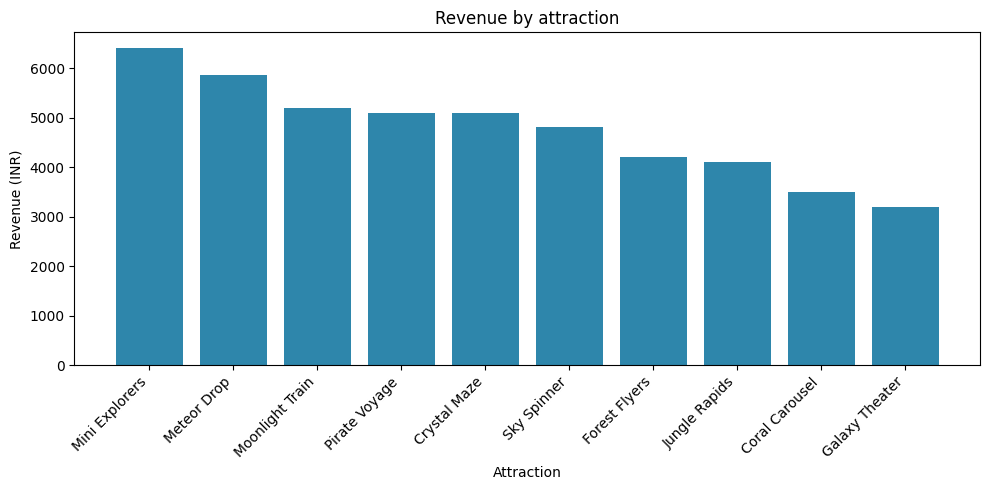

In [0]:
import matplotlib.pyplot as plt

gold_pdf = spark.table("cap_gold_attraction_summary").toPandas()
gold_pdf = gold_pdf.dropna(subset=["attraction_name"]).sort_values("total_revenue", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(gold_pdf["attraction_name"], gold_pdf["total_revenue"], color="#2E86AB")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Attraction")
plt.ylabel("Revenue (INR)")
plt.title("Revenue by attraction")
plt.tight_layout()
plt.show()

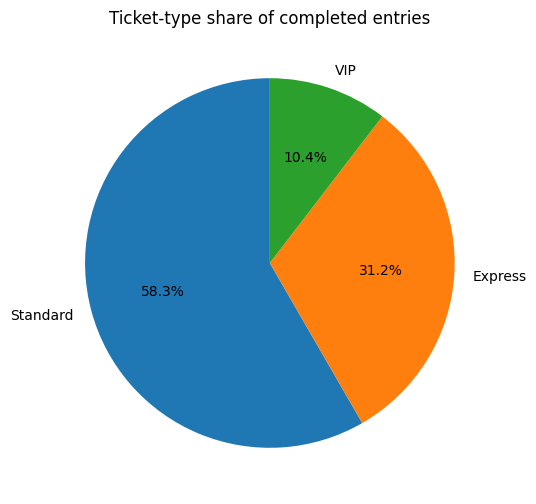

In [0]:
mix_pdf = spark.table("cap_gold_ticket_mix").toPandas().sort_values("completed_entries", ascending=False)

plt.figure(figsize=(6, 6))
plt.pie(mix_pdf["completed_entries"], labels=mix_pdf["ticket_type"], autopct="%1.1f%%", startangle=90)
plt.title("Ticket-type share of completed entries")
plt.show()

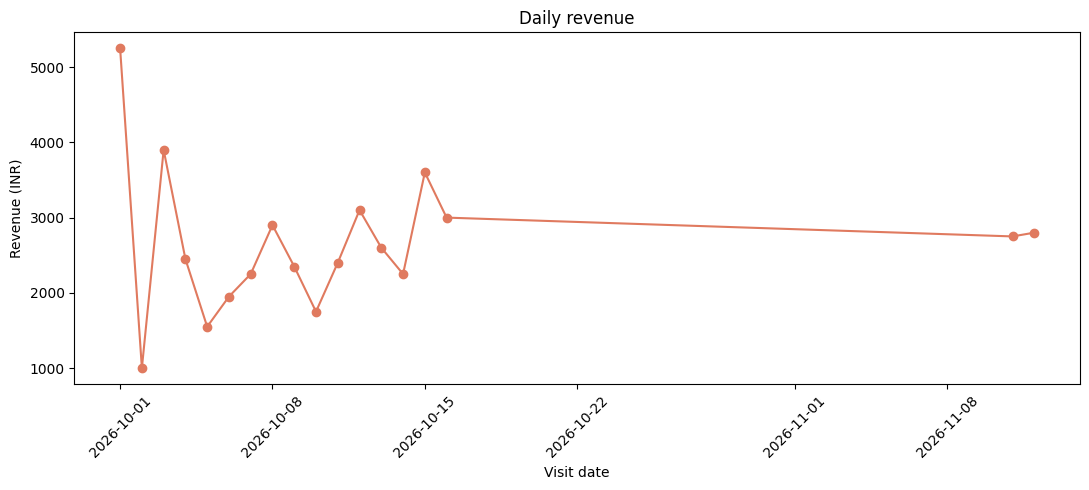

In [0]:
import pandas as pd
import matplotlib.pyplot as plt

daily_pdf = spark.table("cap_gold_daily_revenue").toPandas()
daily_pdf["visit_date"] = pd.to_datetime(daily_pdf["visit_date"])
daily_pdf = daily_pdf.sort_values("visit_date")

plt.figure(figsize=(11, 5))
plt.plot(daily_pdf["visit_date"], daily_pdf["total_revenue"], marker="o", color="#E07A5F")
plt.xticks(rotation=45)
plt.xlabel("Visit date")
plt.ylabel("Revenue (INR)")
plt.title("Daily revenue")
plt.tight_layout()
plt.show()

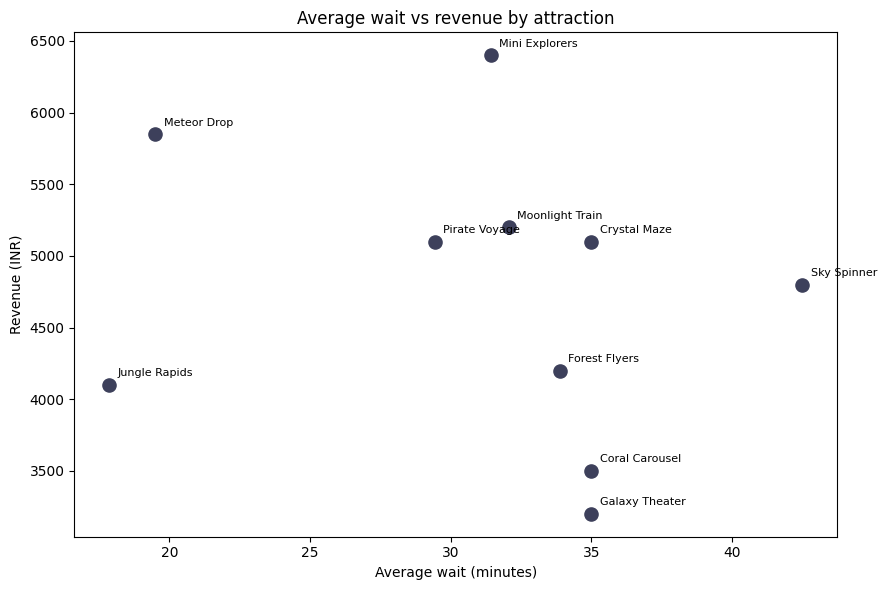

In [0]:
import matplotlib.pyplot as plt

scatter_pdf = spark.table("cap_gold_attraction_summary").toPandas().dropna(subset=["attraction_name"])

plt.figure(figsize=(9, 6))
plt.scatter(scatter_pdf["avg_wait_minutes"], scatter_pdf["total_revenue"], s=90, color="#3D405B")
for _, row in scatter_pdf.iterrows():
    plt.annotate(row["attraction_name"], (row["avg_wait_minutes"], row["total_revenue"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.xlabel("Average wait (minutes)")
plt.ylabel("Revenue (INR)")
plt.title("Average wait vs revenue by attraction")
plt.tight_layout()
plt.show()

In [0]:
%sql
CREATE OR REPLACE TABLE cap_entries_work
USING DELTA
AS
SELECT DISTINCT entry_id, visitor_id, attraction_id, visit_date, entry_time,
       wait_minutes, ride_minutes, ticket_type, ticket_price, status,
       COALESCE(booking_channel, 'Unknown') AS booking_channel
FROM tp_entries_raw
WHERE wait_minutes >= 0 AND ride_minutes > 0 AND ticket_price > 0;

num_affected_rows,num_inserted_rows


In [0]:
%sql
MERGE INTO cap_entries_work AS t
USING tp_entry_changes AS s
ON t.entry_id = s.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
10,5,0,5


In [0]:
display(
    spark.sql("DESCRIBE HISTORY cap_entries_work")
    .filter("operation = 'MERGE'")
    .select("version", "operation", "operationMetrics")
)

version,operation,operationMetrics
1,MERGE,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3575, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 2553, materializeSourceTimeMs -> 1, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 920, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1575)"


In [0]:
%sql
SELECT 'version_0_before_merge' AS stage, entry_id, status, ticket_price, booking_channel
FROM cap_entries_work VERSION AS OF 0
WHERE entry_id = 1010
UNION ALL
SELECT 'current_after_merge', entry_id, status, ticket_price, booking_channel
FROM cap_entries_work
WHERE entry_id = 1010;

stage,entry_id,status,ticket_price,booking_channel
version_0_before_merge,1010,Cancelled,600.0,Kiosk
current_after_merge,1010,Completed,675.0,App


In [0]:
new_rows = [
    (1150, "V820", "A01", "2026-11-13", "10:00:00", 20, 6, "Express", 600.0, "Completed", "App"),
    (1151, "V821", "A05", "2026-11-13", "11:00:00", 55, 5, "VIP", 900.0, "Completed", "Web"),
    (1152, "V822", "A07", "2026-11-13", "12:00:00", 30, 9, "Standard", 350.0, "Completed", "Kiosk"),
    (1153, "V823", "A03", "2026-11-13", "13:00:00", 15, 10, "Standard", 350.0, "Pending", "Partner")
]
schema_ddl = "entry_id INT, visitor_id STRING, attraction_id STRING, visit_date STRING, entry_time STRING, wait_minutes INT, ride_minutes INT, ticket_type STRING, ticket_price DOUBLE, status STRING, booking_channel STRING"
spark.createDataFrame(new_rows, schema_ddl).write.format("delta").mode("append").saveAsTable("workspace.default.tp_entries_raw")
print(spark.table("workspace.default.tp_entries_raw").count())

137


In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS workspace.tp_dev;

In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS workspace.tp_prod;